# Stage 1 — Data + Signals (Hour 0-2)

Pull OHLCV + Polygon news + Fama-French. Build 8 candidate signals. Tag regime dates.

**This notebook prints diagnostic checks at each step.** The final cell tells you which downstream stages are unblocked. If anything critical is `FAIL`, fix before proceeding.

**Run order:** top to bottom, once. Outputs land in `workspace/data/`.

**Time budget:** 60-90 min, mostly waiting on Polygon (rate-limited free tier).

In [19]:
import os, sys, time, warnings, json
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import requests
import yfinance as yf
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

# ---- CONFIG (CLEAN HISTORICAL WINDOW: 2013-2020) ----
# Window chosen so Kaggle news + yfinance OHLCV both have full coverage.
# Kaggle: 2013-01-01 -> 2020-06-11
# yfinance: all our tickers exist by 2013 (V/MA/GOOGL all IPO'd before)
WORKSPACE = '/Applications/Projects/Hackathons/quantum_ai/workspace'
DATA_DIR = os.path.join(WORKSPACE, 'data')
os.makedirs(DATA_DIR, exist_ok=True)

START_DATE = '2013-01-01'
TRAIN_END  = '2018-12-31'           # train 2013-2018 (~6 years)
TEST_START = '2019-01-01'           # test 2019-2020 (includes COVID March 2020)
END_DATE   = '2020-06-11'           # Kaggle news cutoff

FAST_MODE = False
POLYGON_LOOKBACK_DAYS = 0           # disable recent-only sources for historical window

# ---- DIAGNOSTIC HELPER ----
CHECKS = {}

def check(name, condition, msg='', critical=True):
    status = 'PASS' if condition else ('FAIL' if critical else 'WARN')
    CHECKS[name] = (status, msg)
    icon = '[PASS]' if status == 'PASS' else ('[FAIL]' if status == 'FAIL' else '[WARN]')
    print(f'{icon} {name}: {msg}')
    return condition

print(f'Workspace: {WORKSPACE}')
print(f'Data dir:  {DATA_DIR}')
print(f'Window:    {START_DATE} -> {END_DATE}')
print(f'Train:     {START_DATE} -> {TRAIN_END}')
print(f'Test:      {TEST_START} -> {END_DATE}  (includes COVID March 2020)')
print(f'News source: Kaggle (full coverage 2013-2020), DDG/Benzinga/NewsAPI auto-skip')


Workspace: /Applications/Projects/Hackathons/quantum_ai/workspace
Data dir:  /Applications/Projects/Hackathons/quantum_ai/workspace/data
Window:    2013-01-01 -> 2020-06-11
Train:     2013-01-01 -> 2018-12-31
Test:      2019-01-01 -> 2020-06-11  (includes COVID March 2020)
News source: Kaggle (full coverage 2013-2020), DDG/Benzinga/NewsAPI auto-skip


## 0. Universe + sector taxonomy

In [20]:
TICKER_SECTOR = {
    'AAPL': 'tech', 'MSFT': 'tech', 'GOOGL': 'tech', 'NVDA': 'tech',
    'JPM':  'fin',  'BAC':  'fin',  'V':     'fin',  'MA':   'fin',
    'JNJ':  'hc',   'PFE':  'hc',   'UNH':   'hc',   'LLY':  'hc',
    'WMT':  'cons', 'PG':   'cons', 'KO':    'cons', 'PEP':  'cons',
    'XOM':  'eng',  'CVX':  'eng',  'CAT':   'eng',  'BA':   'eng',
}
TICKERS = list(TICKER_SECTOR)

print(f'{len(TICKERS)} tickers across {len(set(TICKER_SECTOR.values()))} sectors:')
for s in sorted(set(TICKER_SECTOR.values())):
    members = [t for t, sec in TICKER_SECTOR.items() if sec == s]
    print(f'  {s:6s}: {members}')

# Save
pd.Series(TICKER_SECTOR, name='sector').to_csv(os.path.join(DATA_DIR, 'ticker_sector.csv'))
check('Universe: 20 tickers, 5 sectors x 4', len(TICKERS) == 20 and len(set(TICKER_SECTOR.values())) == 5,
      f'{len(TICKERS)} tickers, {len(set(TICKER_SECTOR.values()))} sectors')

20 tickers across 5 sectors:
  cons  : ['WMT', 'PG', 'KO', 'PEP']
  eng   : ['XOM', 'CVX', 'CAT', 'BA']
  fin   : ['JPM', 'BAC', 'V', 'MA']
  hc    : ['JNJ', 'PFE', 'UNH', 'LLY']
  tech  : ['AAPL', 'MSFT', 'GOOGL', 'NVDA']
[PASS] Universe: 20 tickers, 5 sectors x 4: 20 tickers, 5 sectors


True

## 1. OHLCV from yfinance

In [21]:
print(f'Pulling OHLCV: {len(TICKERS)} tickers from {START_DATE} to {END_DATE}...')
raw = yf.download(TICKERS, start=START_DATE, end=END_DATE, progress=False, auto_adjust=True)

if isinstance(raw.columns, pd.MultiIndex):
    prices  = raw['Close']
    highs   = raw['High']
    lows    = raw['Low']
    volumes = raw['Volume']
else:
    raise RuntimeError('Expected multi-index columns from yfinance; got single index')

prices  = prices.reindex(columns=TICKERS)
highs   = highs.reindex(columns=TICKERS)
lows    = lows.reindex(columns=TICKERS)
volumes = volumes.reindex(columns=TICKERS)

prices.to_parquet(os.path.join(DATA_DIR, 'prices.parquet'))
highs.to_parquet(os.path.join(DATA_DIR, 'highs.parquet'))
lows.to_parquet(os.path.join(DATA_DIR, 'lows.parquet'))
volumes.to_parquet(os.path.join(DATA_DIR, 'volumes.parquet'))

n_dates = len(prices)
n_missing = prices.isna().sum().sum()
missing_pct = n_missing / prices.size * 100
missing_per_ticker = prices.isna().sum()
tickers_with_data = (missing_per_ticker < len(prices) * 0.5).sum()

print(f'\nDate range: {prices.index[0].date()} -> {prices.index[-1].date()}')
print(f'Trading days: {n_dates}')
print(f'Missing values: {n_missing} ({missing_pct:.1f}%)')
print(f'\nTickers with usable history: {tickers_with_data}/{len(TICKERS)}')
if missing_per_ticker.max() > 5:
    print('Per-ticker missing:')
    print(missing_per_ticker.sort_values(ascending=False).head(5))

check('OHLCV: enough history (>=1500 days)', n_dates >= 1500,
      f'{n_dates} trading days')
check('OHLCV: low missing rate (<2%)', missing_pct < 2.0,
      f'{missing_pct:.2f}% missing')
check('OHLCV: 18+ tickers usable', tickers_with_data >= 18,
      f'{tickers_with_data}/{len(TICKERS)} tickers')


Pulling OHLCV: 20 tickers from 2013-01-01 to 2020-06-11...

Date range: 2013-01-02 -> 2020-06-10
Trading days: 1873
Missing values: 0 (0.0%)

Tickers with usable history: 20/20
[PASS] OHLCV: enough history (>=1500 days): 1873 trading days
[PASS] OHLCV: low missing rate (<2%): 0.00% missing
[PASS] OHLCV: 18+ tickers usable: 20/20 tickers


np.True_

In [22]:
returns = prices.pct_change()
returns.to_parquet(os.path.join(DATA_DIR, 'returns.parquet'))

daily_std = returns.std()
ann_vol = daily_std * np.sqrt(252) * 100
ann_ret = returns.mean() * 252 * 100

print('Per-ticker annualized stats:')
stats = pd.DataFrame({'ann_return_%': ann_ret.round(1), 'ann_vol_%': ann_vol.round(1)})
print(stats.to_string())

extreme_vol = ((daily_std > 0.08) | (daily_std < 0.005)).sum()
check('Returns: vols in reasonable range', extreme_vol == 0,
      f'{extreme_vol} tickers with anomalous daily vol')

Per-ticker annualized stats:
        ann_return_%  ann_vol_%
Ticker                         
AAPL            25.9       27.6
MSFT            32.2       26.2
GOOGL           22.0       25.3
NVDA            55.0       41.1
JPM             17.7       26.2
BAC             16.8       30.4
V               25.8       24.5
MA              28.4       26.0
JNJ             14.3       18.1
PFE             10.0       19.9
UNH             28.2       26.0
LLY             20.5       23.3
WMT             12.0       20.0
PG              12.1       18.5
KO               8.1       17.8
PEP             13.5       18.5
XOM             -1.0       23.3
CVX              6.3       27.8
CAT             11.5       27.7
BA              22.0       36.1
[PASS] Returns: vols in reasonable range: 0 tickers with anomalous daily vol


np.True_

## 2. News + sentiment (Kaggle → DuckDuckGo → Polygon)

Three independent sources. Cell merges them — each fills cells the previous didn't cover.

1. **Kaggle** (`elsabetyemane/financial-news-and-stock-price-integration-dataset`) — multi-year pre-labeled sentiment. Best for training data. Needs `~/.kaggle/kaggle.json`.
2. **DuckDuckGo News** — no auth required, always works. Headline-based sentiment computed locally via TextBlob. Limited to ~recent weeks but no rate limits.
3. **Polygon** — recent ~90 days, pre-tagged sentiment. Optional supplement.

If all three fail → zeros. KTA correctly down-ranks `news_sent` and pipeline still runs.

**If you saw the kagglesdk ImportError last run:** RESTART KERNEL (Kernel → Restart) before re-running this cell. The package was reinstalled but Python cached the broken version.

In [23]:
import subprocess

source_dfs = {}

def empty_df():
    return pd.DataFrame(0.0, index=prices.index, columns=TICKERS)

# ============================================================
# Kaggle — PRIMARY news source for 2013-2020 window
# ============================================================
print('[Kaggle] loading financial-news dataset (2013-2020 historical)...')
try:
    import kagglehub
    from kagglehub import KaggleDatasetAdapter
    from textblob import TextBlob

    kdf = kagglehub.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        'elsabetyemane/financial-news-and-stock-price-integration-dataset',
        'modularization-demo/data/raw_analyst_ratings.csv',
    )
    print(f'[Kaggle] loaded shape={kdf.shape}')

    kdf['date'] = pd.to_datetime(kdf['date'], errors='coerce', utc=True).dt.tz_localize(None).dt.normalize()
    kdf = kdf.dropna(subset=['date', 'headline', 'stock'])
    kdf['stock'] = kdf['stock'].astype(str).str.upper().str.strip()

    # Filter to our 20 tickers AND our date window
    kdf_sub = kdf[
        kdf['stock'].isin(TICKERS) &
        (kdf['date'] >= pd.Timestamp(START_DATE)) &
        (kdf['date'] <= pd.Timestamp(END_DATE))
    ].copy()
    print(f'[Kaggle] rows for our 20 tickers in {START_DATE}->{END_DATE}: {len(kdf_sub):,}')

    if len(kdf_sub) > 0:
        print('[Kaggle] computing TextBlob sentiment on headlines...')
        kdf_sub['sentiment'] = kdf_sub['headline'].astype(str).apply(
            lambda t: float(TextBlob(t).sentiment.polarity))

        agg = (kdf_sub.groupby(['date', 'stock'])['sentiment']
                      .mean().unstack(fill_value=0))
        agg = agg.reindex(index=prices.index, columns=TICKERS, fill_value=0)
        n_kg = int((agg != 0).sum().sum())
        print(f'[Kaggle] coverage: {n_kg:,} cells ({n_kg / agg.size * 100:.1f}% of grid)')
        source_dfs['kaggle'] = agg.copy()

        # Save headlines
        kaggle_headlines = kdf_sub[['date', 'stock', 'headline', 'publisher', 'sentiment']].rename(
            columns={'stock': 'ticker', 'publisher': 'source'})
        kaggle_headlines['url'] = ''
        kaggle_headlines.to_parquet(os.path.join(DATA_DIR, 'kaggle_headlines.parquet'))
        kaggle_headlines.to_parquet(os.path.join(DATA_DIR, 'news_headlines.parquet'))
        print(f'[Kaggle] saved {len(kaggle_headlines):,} headlines')

except Exception as e:
    print(f'[Kaggle] FAILED: {type(e).__name__}: {e}')

# ============================================================
# Recent-only sources skipped (window is 2013-2020)
# ============================================================
print('\n[DDG/Benzinga/NewsAPI] skipped — recent-only sources, no overlap with 2013-2020')

# ============================================================
# Save combined news_sent
# ============================================================
if source_dfs:
    sum_df = sum(df for df in source_dfs.values())
    count_df = sum((df != 0).astype(int) for df in source_dfs.values())
    news_sent = (sum_df / count_df.replace(0, 1)).where(count_df > 0, 0)
else:
    news_sent = empty_df()

news_sent.to_parquet(os.path.join(DATA_DIR, 'news_sent.parquet'))

n_nonzero = int((news_sent != 0).sum().sum())
sources_str = ' + '.join(sorted(source_dfs.keys())) if source_dfs else 'NONE'
print(f'\nFINAL news_sent: source={sources_str}')
print(f'Coverage: {n_nonzero:,} cells ({n_nonzero / news_sent.size * 100:.2f}% of grid)')

check(f'News: source={sources_str}', n_nonzero > 0,
      f'{n_nonzero:,} cells', critical=False)


[Kaggle] loading financial-news dataset (2013-2020 historical)...
[Kaggle] loaded shape=(1407328, 6)
[Kaggle] rows for our 20 tickers in 2013-01-01->2020-06-11: 180
[Kaggle] computing TextBlob sentiment on headlines...
[Kaggle] coverage: 56 cells (0.1% of grid)
[Kaggle] saved 180 headlines

[DDG/Benzinga/NewsAPI] skipped — recent-only sources, no overlap with 2013-2020

FINAL news_sent: source=kaggle
Coverage: 56 cells (0.15% of grid)
[PASS] News: source=kaggle: 56 cells


True

## 2.6 Benzinga News V2 (Polygon premium news endpoint)

Replaces the broken `/v2/reference/news`. Pulls richer articles: title + teaser + ticker tags + author. Sentiment via TextBlob on title+teaser. Merges with existing `news_sent` and appends to `news_headlines`.

Requires Polygon plan with Benzinga add-on. If endpoint returns 403, cell exits cleanly (no breakage).

In [24]:
import requests

BENZINGA_LOOKBACK_DAYS = 365   # bump down to 90 if rate-limited

POLYGON_KEY = os.environ.get('POLYGON_API_KEY')
if not POLYGON_KEY:
    print('[Benzinga] POLYGON_API_KEY not set, skipping')
else:
    from textblob import TextBlob
    benzinga_records = []
    benzinga_sent_sum = pd.DataFrame(0.0, index=prices.index, columns=TICKERS)
    benzinga_sent_cnt = pd.DataFrame(0, index=prices.index, columns=TICKERS)

    cutoff = (datetime.now() - timedelta(days=BENZINGA_LOOKBACK_DAYS)).strftime('%Y-%m-%d')
    print(f'[Benzinga] pulling news per ticker from {cutoff}...')

    benzinga_errors = 0
    benzinga_403_seen = False

    for i, ticker in enumerate(TICKERS):
        if benzinga_403_seen:
            break

        url = 'https://api.polygon.io/benzinga/v2/news'
        params = {
            'tickers': ticker,
            'limit': 100,
            'sort': 'published_utc.desc',
            'published_utc.gte': cutoff,
            'apiKey': POLYGON_KEY,
        }
        try:
            r = requests.get(url, params=params, timeout=20)
            if r.status_code == 403:
                print(f'  {ticker}: 403 - Benzinga not in your Polygon plan, skipping rest')
                benzinga_403_seen = True
                continue
            if r.status_code == 429:
                time.sleep(15)
                r = requests.get(url, params=params, timeout=20)
            if r.status_code != 200:
                benzinga_errors += 1
                print(f'  {ticker}: HTTP {r.status_code}')
                time.sleep(1)
                continue

            articles = r.json().get('results', []) or []
            for art in articles:
                try:
                    d_pub = pd.to_datetime(art.get('published_utc'))
                    if d_pub is None or pd.isna(d_pub):
                        continue
                    if d_pub.tz is not None:
                        d_pub = d_pub.tz_localize(None)
                    d = d_pub.normalize()
                    if d not in benzinga_sent_sum.index:
                        continue
                    title = (art.get('title') or '').strip()
                    teaser = (art.get('teaser') or '').strip()
                    if not title:
                        continue
                    polarity = float(TextBlob(title + '. ' + teaser).sentiment.polarity)
                    benzinga_sent_sum.loc[d, ticker] += polarity
                    benzinga_sent_cnt.loc[d, ticker] += 1
                    benzinga_records.append({
                        'date':      d,
                        'ticker':    ticker,
                        'headline':  title,
                        'source':    'Benzinga',
                        'url':       art.get('article_url') or '',
                        'sentiment': polarity,
                    })
                except Exception:
                    continue

            time.sleep(0.3)
        except Exception as e:
            benzinga_errors += 1
            time.sleep(1)
            continue

        if (i + 1) % 5 == 0:
            print(f'  ...{i + 1}/{len(TICKERS)}')

    # Average sentiment per (date, ticker)
    benzinga_sent = (benzinga_sent_sum / benzinga_sent_cnt.replace(0, 1)).where(benzinga_sent_cnt > 0, 0)
    benzinga_sent = benzinga_sent.clip(-1, 1)

    n_bz = int((benzinga_sent != 0).sum().sum())
    print(f'\n[Benzinga] coverage: {n_bz} cells, {len(benzinga_records)} article-level rows, '
          f'errors: {benzinga_errors}')

    if n_bz > 0:
        # Save Benzinga-only artifact
        benzinga_sent.to_parquet(os.path.join(DATA_DIR, 'benzinga_sent.parquet'))

        # MERGE into existing news_sent (mean across sources)
        existing = pd.read_parquet(os.path.join(DATA_DIR, 'news_sent.parquet'))
        ex_mask = (existing != 0).astype(int)
        bz_mask = (benzinga_sent != 0).astype(int)
        total_cnt = ex_mask + bz_mask
        merged = ((existing + benzinga_sent) / total_cnt.replace(0, 1)).where(total_cnt > 0, 0)
        merged.to_parquet(os.path.join(DATA_DIR, 'news_sent.parquet'))
        print(f'Merged into news_sent: {int((merged != 0).sum().sum())} total non-zero cells')

        # MERGE headlines into news_headlines.parquet
        bz_headlines = pd.DataFrame(benzinga_records)
        try:
            existing_h = pd.read_parquet(os.path.join(DATA_DIR, 'news_headlines.parquet'))
            all_h = pd.concat([existing_h, bz_headlines], ignore_index=True)
            all_h = all_h.drop_duplicates(subset=['date', 'ticker', 'headline'])
        except FileNotFoundError:
            all_h = bz_headlines
        all_h.to_parquet(os.path.join(DATA_DIR, 'news_headlines.parquet'))
        print(f'Headlines file now has {len(all_h)} rows (DDG + Benzinga merged)')

        # Sample
        print('\nSample Benzinga headlines (most recent):')
        sample = bz_headlines.sort_values('date', ascending=False).head(8)
        for _, row in sample.iterrows():
            print(f"  {row['date'].date()} [{row['ticker']:5s}] "
                  f"sent={row['sentiment']:+.2f}  {row['headline'][:75]}")

    check('News: Benzinga loaded', n_bz > 0,
          f'{n_bz} cells from Benzinga' if n_bz > 0 else 'Benzinga not available in your plan',
          critical=False)

[Benzinga] pulling news per ticker from 2025-05-30...
  AAPL: 403 - Benzinga not in your Polygon plan, skipping rest

[Benzinga] coverage: 0 cells, 0 article-level rows, errors: 0
[WARN] News: Benzinga loaded: Benzinga not available in your plan


## 2.7 NewsAPI.org (free tier, ~1 month history)

Third independent news source. Free tier limits: 100 req/day, ~1 month of history, ~100 articles per query. Searches by company name OR ticker symbol for broader coverage.

Set `NEWS_API_KEY` env var. Get a free key at https://newsapi.org/register.

Merges into the same `news_sent.parquet` + `news_headlines.parquet` (mean across all sources per cell).

In [25]:
import requests

# Ticker -> company name mapping for broader query matches
TICKER_NAME = {
    'AAPL': 'Apple',           'MSFT': 'Microsoft',         'GOOGL': 'Google',
    'NVDA': 'Nvidia',          'JPM':  'JPMorgan',          'BAC':   'Bank of America',
    'V':    'Visa',            'MA':   'Mastercard',        'JNJ':   'Johnson Johnson',
    'PFE':  'Pfizer',          'UNH':  'UnitedHealth',      'LLY':   'Eli Lilly',
    'WMT':  'Walmart',         'PG':   'Procter Gamble',    'KO':    'Coca-Cola',
    'PEP':  'PepsiCo',         'XOM':  'Exxon',             'CVX':   'Chevron',
    'CAT':  'Caterpillar',     'BA':   'Boeing',
}

NEWSAPI_KEY = "c920a5a008724c24b5f1d720c99d11bd"

if not NEWSAPI_KEY:
    print('[NewsAPI] no NEWS_API_KEY / NEWSAPI_KEY env var set, skipping')
    print('         Get a free key at https://newsapi.org/register')
else:
    from textblob import TextBlob
    newsapi_records = []
    newsapi_sent_sum = pd.DataFrame(0.0, index=prices.index, columns=TICKERS)
    newsapi_sent_cnt = pd.DataFrame(0, index=prices.index, columns=TICKERS)

    cutoff = (datetime.now() - timedelta(days=28)).strftime('%Y-%m-%d')
    print(f'[NewsAPI] pulling from {cutoff} (free tier limit ~30 days)...')

    newsapi_errors = 0
    newsapi_429_seen = False

    for i, ticker in enumerate(TICKERS):
        if newsapi_429_seen:
            print('  hit 429 too many times, stopping early')
            break

        company = TICKER_NAME.get(ticker, ticker)
        q = f'({ticker} OR "{company}") AND (stock OR shares OR earnings OR price)'

        url = 'https://newsapi.org/v2/everything'
        params = {
            'q': q,
            'from': cutoff,
            'sortBy': 'publishedAt',
            'language': 'en',
            'pageSize': 100,
            'apiKey': NEWSAPI_KEY,
        }
        try:
            r = requests.get(url, params=params, timeout=20)
            if r.status_code == 401:
                print(f'  {ticker}: 401 - invalid NEWS_API_KEY, stopping')
                break
            if r.status_code == 426:
                print(f'  {ticker}: 426 - free tier limit (date range exceeded)')
                continue
            if r.status_code == 429:
                print(f'  {ticker}: 429 - daily rate limit hit, sleeping 10s')
                time.sleep(10)
                r = requests.get(url, params=params, timeout=20)
                if r.status_code == 429:
                    newsapi_429_seen = True
                    continue
            if r.status_code != 200:
                newsapi_errors += 1
                print(f'  {ticker}: HTTP {r.status_code}')
                time.sleep(1)
                continue

            data = r.json()
            articles = data.get('articles', []) or []

            for art in articles:
                try:
                    d_pub = pd.to_datetime(art.get('publishedAt'))
                    if d_pub is None or pd.isna(d_pub):
                        continue
                    if d_pub.tz is not None:
                        d_pub = d_pub.tz_localize(None)
                    d = d_pub.normalize()
                    if d not in newsapi_sent_sum.index:
                        continue
                    title = (art.get('title') or '').strip()
                    desc = (art.get('description') or '').strip()
                    if not title or title == '[Removed]':
                        continue
                    polarity = float(TextBlob(title + '. ' + desc).sentiment.polarity)
                    newsapi_sent_sum.loc[d, ticker] += polarity
                    newsapi_sent_cnt.loc[d, ticker] += 1
                    src_name = (art.get('source') or {}).get('name', 'NewsAPI')
                    newsapi_records.append({
                        'date':      d,
                        'ticker':    ticker,
                        'headline':  title,
                        'source':    src_name,
                        'url':       art.get('url') or '',
                        'sentiment': polarity,
                    })
                except Exception:
                    continue

            time.sleep(1.2)  # NewsAPI free tier rate limit
        except Exception as e:
            newsapi_errors += 1
            time.sleep(1)
            continue

        if (i + 1) % 5 == 0:
            print(f'  ...{i + 1}/{len(TICKERS)}')

    # Average sentiment per (date, ticker)
    newsapi_sent = (newsapi_sent_sum / newsapi_sent_cnt.replace(0, 1)).where(newsapi_sent_cnt > 0, 0)
    newsapi_sent = newsapi_sent.clip(-1, 1)

    n_na = int((newsapi_sent != 0).sum().sum())
    print(f'\n[NewsAPI] coverage: {n_na} cells, {len(newsapi_records)} article rows, '
          f'errors: {newsapi_errors}')

    if n_na > 0:
        # Save NewsAPI-only artifact
        newsapi_sent.to_parquet(os.path.join(DATA_DIR, 'newsapi_sent.parquet'))

        # MERGE into existing news_sent
        existing = pd.read_parquet(os.path.join(DATA_DIR, 'news_sent.parquet'))
        ex_mask = (existing != 0).astype(int)
        na_mask = (newsapi_sent != 0).astype(int)
        total_cnt = ex_mask + na_mask
        merged = ((existing + newsapi_sent) / total_cnt.replace(0, 1)).where(total_cnt > 0, 0)
        merged.to_parquet(os.path.join(DATA_DIR, 'news_sent.parquet'))
        print(f'Merged into news_sent: {int((merged != 0).sum().sum())} total non-zero cells')

        # MERGE headlines
        na_headlines = pd.DataFrame(newsapi_records)
        try:
            existing_h = pd.read_parquet(os.path.join(DATA_DIR, 'news_headlines.parquet'))
            all_h = pd.concat([existing_h, na_headlines], ignore_index=True)
            all_h = all_h.drop_duplicates(subset=['date', 'ticker', 'headline'])
        except FileNotFoundError:
            all_h = na_headlines
        all_h.to_parquet(os.path.join(DATA_DIR, 'news_headlines.parquet'))
        print(f'Headlines file now: {len(all_h)} rows (combined across all sources)')

        # Sample
        print('\nSample NewsAPI headlines (most recent):')
        sample = na_headlines.sort_values('date', ascending=False).head(8)
        for _, row in sample.iterrows():
            print(f"  {row['date'].date()} [{row['ticker']:5s}] "
                  f"[{row['source'][:18]:18s}] {row['headline'][:70]}")

    check('News: NewsAPI loaded', n_na > 0,
          f'{n_na} cells from NewsAPI' if n_na > 0 else 'No coverage (key invalid or no recent articles)',
          critical=False)

[NewsAPI] pulling from 2026-05-02 (free tier limit ~30 days)...
  ...5/20
  ...10/20
  ...15/20
  ...20/20

[NewsAPI] coverage: 0 cells, 0 article rows, errors: 0
[WARN] News: NewsAPI loaded: No coverage (key invalid or no recent articles)


## 3. Fama-French 5-factor (free, Tuck)

In [26]:
print('Pulling Fama-French 5-factor daily...')
ff = None
try:
    try:
        from pandas_datareader.famafrench import FamaFrenchReader
    except ImportError:
        print('Installing pandas-datareader...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pandas-datareader'])
        from pandas_datareader.famafrench import FamaFrenchReader

    reader = FamaFrenchReader('F-F_Research_Data_5_Factors_2x3_daily',
                              start=START_DATE)
    ff = reader.read()[0] / 100.0
    ff.index = pd.to_datetime(ff.index)
    ff = ff.reindex(prices.index).ffill()
    print(f'Loaded FF factors: {list(ff.columns)}')
    print(f'Rows: {len(ff)}, NaN rows: {ff.isna().any(axis=1).sum()}')
    check('Fama-French: loaded', True, f'{ff.shape[1]} factors, {len(ff)} rows')
except Exception as e:
    print(f'Fama-French pull failed: {type(e).__name__}: {e}')
    print('Falling back to zero factors (factor signals will be weak)')
    ff = pd.DataFrame(0.0, index=prices.index,
                       columns=['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF'])
    check('Fama-French: loaded', False, f'fallback: {e}', critical=False)

ff.to_parquet(os.path.join(DATA_DIR, 'fama_french.parquet'))

Pulling Fama-French 5-factor daily...
Loaded FF factors: ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']
Rows: 1873, NaN rows: 0
[PASS] Fama-French: loaded: 6 factors, 1873 rows


## 4. Build the 8 candidate signals

In [27]:
def rsi(series, n=14):
    delta = series.diff()
    gain = delta.where(delta > 0, 0).rolling(n).mean()
    loss = -delta.where(delta < 0, 0).rolling(n).mean()
    rs = gain / loss.replace(0, np.nan)
    return 100 - (100 / (1 + rs))

# 14 BASE signals (original 8 + 6 new)
BASE_SIGNALS = [
    'mom_5d', 'mom_20d', 'mom_60d',                 # momentum at multiple horizons
    'rev_1d',                                        # mean reversion
    'vol_20d', 'vol_of_vol',                         # vol + vol-of-vol
    'rsi_14',
    'news_sent',
    'vol_ratio', 'spread_prox',
    'vol_adj_mom', 'dist_to_high', 'dist_to_low',   # new: vol-adj momentum + extremes
    'pct_above_200ma',                               # new: long-term trend
]

signal_panels = {}
for t in TICKERS:
    r = returns[t]
    p = prices[t]
    sig = pd.DataFrame(index=prices.index)
    # Original 8
    sig['mom_5d']         = r.rolling(5).sum()
    sig['mom_20d']        = r.rolling(20).sum()
    sig['rev_1d']         = -r
    sig['vol_20d']        = r.rolling(20).std()
    sig['rsi_14']         = rsi(p)
    sig['news_sent']      = news_sent[t].rolling(3).mean()
    sig['vol_ratio']      = r.rolling(5).std() / r.rolling(60).std().replace(0, np.nan)
    sig['spread_prox']    = (highs[t] - lows[t]) / p
    # 6 new
    sig['mom_60d']        = r.rolling(60).sum()
    sig['vol_of_vol']     = sig['vol_20d'].rolling(20).std()
    sig['vol_adj_mom']    = sig['mom_20d'] / sig['vol_20d'].replace(0, np.nan)
    sig['dist_to_high']   = (p - p.rolling(60).max()) / p.rolling(60).max()
    sig['dist_to_low']    = (p - p.rolling(60).min()) / p.rolling(60).min().replace(0, np.nan)
    sig['pct_above_200ma'] = (p - p.rolling(200).mean()) / p.rolling(200).mean()
    signal_panels[t] = sig

# ===== Cross-sectional rank normalization (THE big IC lift) =====
print('Adding cross-sectional rank-normalized versions of each signal...')
RANK_SIGNALS = []
for s in BASE_SIGNALS:
    wide = pd.DataFrame({t: signal_panels[t][s] for t in TICKERS})
    wide_rank = wide.rank(axis=1, pct=True)          # per-date rank in [0, 1]
    rank_name = s + '_rank'
    RANK_SIGNALS.append(rank_name)
    for t in TICKERS:
        signal_panels[t][rank_name] = wide_rank[t]

SIGNALS = BASE_SIGNALS + RANK_SIGNALS
signals_long = pd.concat({t: signal_panels[t][SIGNALS] for t in TICKERS}, axis=1)
signals_long.to_parquet(os.path.join(DATA_DIR, 'signals.parquet'))

print(f'Signals: {len(BASE_SIGNALS)} base + {len(RANK_SIGNALS)} ranked = {len(SIGNALS)} total')
print(f'Signals shape: {signals_long.shape}')
print(f'Date range: {signals_long.index[0].date()} -> {signals_long.index[-1].date()}')

check('Signals: 14 base + 14 ranked built',
      signals_long.shape[1] == len(TICKERS) * len(SIGNALS),
      f'{signals_long.shape[1]} columns ({len(TICKERS)} x {len(SIGNALS)})')


Adding cross-sectional rank-normalized versions of each signal...
Signals: 14 base + 14 ranked = 28 total
Signals shape: (1873, 560)
Date range: 2013-01-02 -> 2020-06-10
[PASS] Signals: 14 base + 14 ranked built: 560 columns (20 x 28)


True

In [28]:
# Per-signal NaN rate + variance — is each signal usable?
print('Per-signal usability check:')
print(f'{"signal":12s} {"NaN %":>7s}  {"std":>10s}  {"valid rows":>12s}  {"verdict":>10s}')
print('-' * 65)

for s in SIGNALS:
    cols_for_s = [c for c in signals_long.columns if c[1] == s]
    sub = signals_long.loc[:, cols_for_s]
    nan_pct = float(sub.isna().sum().sum()) / sub.size * 100
    std = float(np.nanstd(sub.values))               # scalar — avoids Series ambiguity
    valid_rows = int(sub.dropna(how='all').shape[0])
    usable = bool((nan_pct < 30) and (std > 1e-6))
    verdict = 'OK' if usable else 'WEAK'
    print(f'{s:12s} {nan_pct:7.1f}  {std:10.4f}  {valid_rows:12d}  {verdict:>10s}')
    check(f'Signal {s}: usable', usable, f'NaN={nan_pct:.1f}%, std={std:.4f}',
          critical=(s != 'news_sent'))   # news_sent failure is non-critical

Per-signal usability check:
signal         NaN %         std    valid rows     verdict
-----------------------------------------------------------------
mom_5d           0.3      0.0348          1868          OK
[PASS] Signal mom_5d: usable: NaN=0.3%, std=0.0348
mom_20d          1.1      0.0662          1853          OK
[PASS] Signal mom_20d: usable: NaN=1.1%, std=0.0662
mom_60d          3.2      0.1066          1813          OK
[PASS] Signal mom_60d: usable: NaN=3.2%, std=0.1066
rev_1d           0.1      0.0163          1872          OK
[PASS] Signal rev_1d: usable: NaN=0.1%, std=0.0163
vol_20d          1.1      0.0092          1853          OK
[PASS] Signal vol_20d: usable: NaN=1.1%, std=0.0092
vol_of_vol       2.1      0.0025          1834          OK
[PASS] Signal vol_of_vol: usable: NaN=2.1%, std=0.0025
rsi_14           0.7     16.7024          1860          OK
[PASS] Signal rsi_14: usable: NaN=0.7%, std=16.7024
news_sent        0.1      0.0033          1871          OK
[PASS] Sig

## 5. Regime tags (for Q-Atlas demo)

Tag known event dates so Q-Atlas can show analogs with human-readable labels. Quick heuristic: abnormal-volume days (likely earnings) + FOMC-like Wednesdays.

In [29]:
regime_tags = pd.Series('', index=prices.index, name='regime_tag', dtype=object)

# 1. Earnings-like days: vol z-score > 3
for t in TICKERS:
    vol_z = (volumes[t] - volumes[t].rolling(30).mean()) / volumes[t].rolling(30).std()
    spike_days = vol_z[vol_z > 3.0].index
    for d in spike_days:
        existing = regime_tags.loc[d]
        regime_tags.loc[d] = f'{existing}, {t}_volspike'.strip(', ') if existing else f'{t}_volspike'

# 2. FOMC days (3rd Wed of FOMC months — rough heuristic)
fomc_months = [1, 3, 5, 6, 7, 9, 11, 12]
for year in range(int(START_DATE[:4]), 2027):
    for m in fomc_months:
        d = pd.Timestamp(year, m, 1)
        wed_count = 0
        while d.month == m:
            if d.weekday() == 2:
                wed_count += 1
                if wed_count == 3:
                    if d in regime_tags.index:
                        existing = regime_tags.loc[d]
                        regime_tags.loc[d] = f'{existing}, FOMC'.strip(', ') if existing else 'FOMC'
                    break
            d += pd.Timedelta(days=1)

regime_tags.to_frame().to_parquet(os.path.join(DATA_DIR, 'regime_tags.parquet'))

n_tagged = (regime_tags != '').sum()
print(f'Tagged {n_tagged} dates')
print('\nSample tagged dates:')
print(regime_tags[regime_tags != ''].head(15).to_string())

check('Regime tags: >=20 dates labeled', n_tagged >= 20,
      f'{n_tagged} dates have regime labels (more = better Q-Atlas demos)',
      critical=False)

Tagged 499 dates

Sample tagged dates:
Date
2013-01-16                                                 FOMC
2013-02-13                          NVDA_volspike, PEP_volspike
2013-02-15                                         WMT_volspike
2013-02-19                                         UNH_volspike
2013-03-15    MSFT_volspike, JPM_volspike, BAC_volspike, JNJ...
2013-03-20                                                 FOMC
2013-03-22                                         PEP_volspike
2013-04-02                                         UNH_volspike
2013-04-11                         MSFT_volspike, NVDA_volspike
2013-04-16                                          KO_volspike
2013-04-17                                        AAPL_volspike
2013-04-18                                         PEP_volspike
2013-04-19                                       GOOGL_volspike
2013-04-22                                         CAT_volspike
2013-04-24                                          PG_volsp

np.True_

## 5.5 Meta-features for QSVM (orthogonal to alpha signals)

These are deliberately DIFFERENT from the 14 alpha signals — they capture context the alpha model can't see. The QSVM meta-labeler uses these to predict P(alpha signal correct):

- `vol_regime`: current vol relative to long-term
- `news_count_3d`: number of news articles past 3 days (attention proxy)
- `news_disp_3d`: dispersion of news sentiment
- `vol_z_30d`: volume z-score (unusual activity)
- `dow`, `month_end`, `quarter_end`: calendar effects

Saved to `data/meta_features.parquet` for Stage 3 to load.

In [30]:
print('Building orthogonal meta-features for QSVM...')

# Date-level features (same for all tickers)
dow_series         = pd.Series(prices.index.dayofweek, index=prices.index)
month_end_series   = pd.Series(prices.index.is_month_end.astype(int), index=prices.index)
quarter_end_series = pd.Series(prices.index.is_quarter_end.astype(int), index=prices.index)

meta_panels = {}
for t in TICKERS:
    r = returns[t]
    v = volumes[t]
    meta = pd.DataFrame(index=prices.index)
    meta['vol_regime']    = r.rolling(5).std() / r.rolling(60).std().replace(0, np.nan)
    meta['news_count_3d'] = (news_sent[t] != 0).rolling(3).sum()
    meta['news_disp_3d']  = news_sent[t].rolling(3).std()
    meta['vol_z_30d']     = (v - v.rolling(30).mean()) / v.rolling(30).std().replace(0, np.nan)
    meta['dow']           = dow_series
    meta['month_end']     = month_end_series
    meta['quarter_end']   = quarter_end_series
    meta_panels[t] = meta

META_FEATURES = list(meta_panels[TICKERS[0]].columns)
meta_long = pd.concat({t: meta_panels[t] for t in TICKERS}, axis=1)
meta_long.to_parquet(os.path.join(DATA_DIR, 'meta_features.parquet'))

print(f'Meta features: {META_FEATURES}')
print(f'Shape: {meta_long.shape}  ({len(META_FEATURES)} features x {len(TICKERS)} tickers)')

# Diagnostics: NaN rate per feature
print(f'\nPer-feature usability (NaN%):')
for f in META_FEATURES:
    cols = [(t, f) for t in TICKERS if (t, f) in meta_long.columns]
    sub = meta_long.loc[:, cols]
    nan_pct = float(sub.isna().sum().sum()) / sub.size * 100
    std = float(np.nanstd(sub.values))
    print(f'  {f:18s}: NaN={nan_pct:5.1f}%  std={std:.4f}')

check('Meta features: built',
      meta_long.shape[1] == len(TICKERS) * len(META_FEATURES),
      f'{len(META_FEATURES)} orthogonal features x {len(TICKERS)} tickers')

Building orthogonal meta-features for QSVM...
Meta features: ['vol_regime', 'news_count_3d', 'news_disp_3d', 'vol_z_30d', 'dow', 'month_end', 'quarter_end']
Shape: (1873, 140)  (7 features x 20 tickers)

Per-feature usability (NaN%):
  vol_regime        : NaN=  3.2%  std=0.4792
  news_count_3d     : NaN=  0.1%  std=0.0792
  news_disp_3d      : NaN=  0.1%  std=0.0043
  vol_z_30d         : NaN=  1.5%  std=1.0490
  dow               : NaN=  0.0%  std=1.4004
  month_end         : NaN=  0.0%  std=0.1789
  quarter_end       : NaN=  0.0%  std=0.1002
[PASS] Meta features: built: 7 orthogonal features x 20 tickers


True

## 6. Forward returns (Stage 2/3 labels)

In [31]:
fwd_1d = returns.shift(-1)
fwd_5d = returns.rolling(5).sum().shift(-5)

fwd_1d.to_parquet(os.path.join(DATA_DIR, 'forward_returns_1d.parquet'))
fwd_5d.to_parquet(os.path.join(DATA_DIR, 'forward_returns_5d.parquet'))

pos_rate = (fwd_1d > 0).stack().mean()
n_valid_1d = fwd_1d.dropna(how='all').shape[0]
n_valid_5d = fwd_5d.dropna(how='all').shape[0]

print(f'1d forward returns: {n_valid_1d} valid days')
print(f'5d forward returns: {n_valid_5d} valid days')
print(f'1d positive return rate: {pos_rate:.2%}')

check('Forward labels: balanced classes', 0.40 < pos_rate < 0.60,
      f'{pos_rate:.2%} positive (need [40%, 60%] for stable meta-classifier)')

1d forward returns: 1872 valid days
5d forward returns: 1868 valid days
1d positive return rate: 52.51%
[PASS] Forward labels: balanced classes: 52.51% positive (need [40%, 60%] for stable meta-classifier)


np.True_

## 7. Signal usefulness — IC + correlation matrix

The critical check. For each of the 8 signals, compute Information Coefficient (Spearman correlation between signal value and next-day return). Then compute pairwise signal-signal correlations to verify diversity.

**Stage 2 needs at least 3 signals with |IC| > 0.01** to have something to learn from.

In [32]:
# IC measured against 5-DAY forward return (less noisy than 1-day)
TARGET_LABEL = 'fwd_5d'
target_series = fwd_5d

ic_results = {}
print(f'IC vs {TARGET_LABEL} (5-day forward return — less noisy than 1d)')
print(f'{"signal":24s} {"mean IC":>10s}  {"|IC|":>8s}  {"IC stderr":>10s}  {"IR-like":>10s}')
print('-' * 70)

for s in SIGNALS:
    ics = []
    for t in TICKERS:
        sig_vals = signal_panels[t][s]
        fwd_vals = target_series[t]
        df_pair = pd.concat([sig_vals, fwd_vals], axis=1).dropna()
        if len(df_pair) < 30:
            continue
        rho, _ = spearmanr(df_pair.iloc[:, 0], df_pair.iloc[:, 1])
        if not np.isnan(rho):
            ics.append(rho)
    if not ics:
        ic_results[s] = np.nan
        continue
    mean_ic = np.mean(ics)
    se = np.std(ics) / np.sqrt(len(ics))
    ir_like = abs(mean_ic) / (np.std(ics) + 1e-9)
    ic_results[s] = mean_ic
    print(f'{s:24s} {mean_ic:10.4f}  {abs(mean_ic):8.4f}  {se:10.4f}  {ir_like:10.2f}')

# Useful signals: |IC| > threshold
THRESHOLD = 0.01
n_useful = sum(1 for ic in ic_results.values() if not np.isnan(ic) and abs(ic) > THRESHOLD)
print(f'\nSignals with |IC| > {THRESHOLD}: {n_useful} / {len(SIGNALS)}')

check(f'Signals: >=3 with predictive power vs {TARGET_LABEL}',
      n_useful >= 3,
      f'{n_useful}/{len(SIGNALS)} have |IC| > {THRESHOLD}')

ic_series = pd.Series(ic_results).abs().sort_values(ascending=False)
ic_series.to_csv(os.path.join(DATA_DIR, 'ic_ranking.csv'))
print(f'\nTop signals by |IC vs {TARGET_LABEL}|:')
print(ic_series.head(10).to_string())

# Compare: did rank versions beat raw?
print(f'\n=== Raw vs Rank-normalized IC delta ===')
print(f'{"base":18s} {"raw IC":>10s}  {"rank IC":>10s}  {"delta":>8s}')
print('-' * 55)
for base in BASE_SIGNALS:
    raw_ic = abs(ic_results.get(base, 0))
    rank_ic = abs(ic_results.get(base + '_rank', 0))
    delta = rank_ic - raw_ic
    marker = '+' if delta > 0 else ' '
    print(f'{base:18s} {raw_ic:10.4f}  {rank_ic:10.4f}  {marker}{delta:7.4f}')


IC vs fwd_5d (5-day forward return — less noisy than 1d)
signal                      mean IC      |IC|   IC stderr     IR-like
----------------------------------------------------------------------
mom_5d                      -0.0447    0.0447      0.0121        0.83
mom_20d                     -0.0467    0.0467      0.0118        0.88
mom_60d                     -0.0669    0.0669      0.0103        1.45
rev_1d                       0.0350    0.0350      0.0069        1.14
vol_20d                      0.0526    0.0526      0.0068        1.72
vol_of_vol                   0.0379    0.0379      0.0095        0.90
rsi_14                      -0.0619    0.0619      0.0118        1.18
news_sent                    0.0247    0.0247      0.0122        0.68
vol_ratio                    0.0180    0.0180      0.0101        0.40
spread_prox                  0.0404    0.0404      0.0070        1.29
vol_adj_mom                 -0.0561    0.0561      0.0111        1.13
dist_to_high                -0.0

In [33]:
# Signal-signal correlation matrix (avg across tickers)
print('Pairwise signal correlation (avg across tickers):')
sig_corr = pd.DataFrame(index=SIGNALS, columns=SIGNALS, dtype=float)

for s1 in SIGNALS:
    for s2 in SIGNALS:
        rhos = []
        for t in TICKERS:
            df_pair = pd.concat([signal_panels[t][s1], signal_panels[t][s2]], axis=1).dropna()
            if len(df_pair) < 30:
                continue
            rho, _ = spearmanr(df_pair.iloc[:, 0], df_pair.iloc[:, 1])
            if not np.isnan(rho):
                rhos.append(rho)
        sig_corr.loc[s1, s2] = np.mean(rhos) if rhos else np.nan

print(sig_corr.round(2).to_string())
sig_corr.to_csv(os.path.join(DATA_DIR, 'signal_correlations.csv'))

# Check: top 5-6 signals by IC should not all be highly correlated
top_signals = ic_series.head(6).index.tolist()
top_corr = sig_corr.loc[top_signals, top_signals].abs()
# Off-diagonal max
np.fill_diagonal(top_corr.values, 0)
max_offdiag = top_corr.max().max()

print(f'\nTop-6 signals: {top_signals}')
print(f'Max off-diagonal correlation among top-6: {max_offdiag:.2f}')
check('Signal diversity: top-6 not over-correlated', max_offdiag < 0.85,
      f'max pairwise |corr|={max_offdiag:.2f} (need <0.85 so KTA picks diverse winners)',
      critical=False)

Pairwise signal correlation (avg across tickers):
                      mom_5d  mom_20d  mom_60d  rev_1d  vol_20d  vol_of_vol  rsi_14  news_sent  vol_ratio  spread_prox  vol_adj_mom  dist_to_high  dist_to_low  pct_above_200ma  mom_5d_rank  mom_20d_rank  mom_60d_rank  rev_1d_rank  vol_20d_rank  vol_of_vol_rank  rsi_14_rank  news_sent_rank  vol_ratio_rank  spread_prox_rank  vol_adj_mom_rank  dist_to_high_rank  dist_to_low_rank  pct_above_200ma_rank
mom_5d                  1.00     0.44     0.24   -0.39     0.02        0.04    0.52       0.02      -0.08        -0.10         0.43          0.45         0.39             0.25         0.72          0.34          0.19        -0.29          0.01             0.02         0.41           -0.02            0.00             -0.00              0.34               0.37              0.28                  0.18
mom_20d                 0.44     1.00     0.51   -0.19    -0.15       -0.02    0.78       0.01      -0.25        -0.17         0.96          0.68   

np.True_

## 7.7 Master dataset — all trade info + news per (date, ticker)

Single tidy DataFrame, one row per `(timestamp, ticker)`. Combines:
- OHLCV (price, high, low, volume)
- Today's return + forward returns (labels for Stage 2/3)
- All 8 signals from Section 4
- Sector + regime tags
- News sentiment today AND yesterday (numeric, from `news_sent.parquet`)
- **Top-3 news headlines today AND yesterday (text, pipe-separated)**
- News article count today

Saved as `data/master_dataset.parquet`. This is the input for Stage 2 alpha models and Stage 5.5 Q-Atlas retrieval.

In [34]:
from IPython.display import display

# ---- Load everything Stage 1 produced ----
prices    = pd.read_parquet(os.path.join(DATA_DIR, 'prices.parquet'))
highs     = pd.read_parquet(os.path.join(DATA_DIR, 'highs.parquet'))
lows      = pd.read_parquet(os.path.join(DATA_DIR, 'lows.parquet'))
volumes   = pd.read_parquet(os.path.join(DATA_DIR, 'volumes.parquet'))
returns   = pd.read_parquet(os.path.join(DATA_DIR, 'returns.parquet'))
fwd_1d    = pd.read_parquet(os.path.join(DATA_DIR, 'forward_returns_1d.parquet'))
fwd_5d    = pd.read_parquet(os.path.join(DATA_DIR, 'forward_returns_5d.parquet'))
signals_long = pd.read_parquet(os.path.join(DATA_DIR, 'signals.parquet'))
news_sent = pd.read_parquet(os.path.join(DATA_DIR, 'news_sent.parquet'))
regime_tags = pd.read_parquet(os.path.join(DATA_DIR, 'regime_tags.parquet'))['regime_tag']
ticker_sector = pd.read_csv(os.path.join(DATA_DIR, 'ticker_sector.csv'), index_col=0)['sector'].to_dict()

try:
    headlines_df = pd.read_parquet(os.path.join(DATA_DIR, 'news_headlines.parquet'))
    headlines_df['date'] = pd.to_datetime(headlines_df['date']).dt.normalize()
    if 'sentiment' not in headlines_df.columns:
        headlines_df['sentiment'] = 0.0
    print(f'Loaded {len(headlines_df):,} headlines for join')
except FileNotFoundError:
    headlines_df = pd.DataFrame(columns=['date', 'ticker', 'headline', 'source', 'sentiment'])
    print('news_headlines.parquet not found, news columns will be empty')

# ---- Helper: wide -> long ----
def stack_wide(df, name):
    out = df.stack(dropna=False)
    out.name = name
    out.index = out.index.set_names(['timestamp', 'ticker'])
    return out

# ---- Step 1: stack all OHLCV + returns + sentiment ----
parts = {
    'price':            stack_wide(prices,    'price'),
    'high':             stack_wide(highs,     'high'),
    'low':              stack_wide(lows,      'low'),
    'volume':           stack_wide(volumes,   'volume'),
    'return_1d':        stack_wide(returns,   'return_1d'),
    'fwd_return_1d':    stack_wide(fwd_1d,    'fwd_return_1d'),
    'fwd_return_5d':    stack_wide(fwd_5d,    'fwd_return_5d'),
    'news_sent_today':  stack_wide(news_sent, 'news_sent_today'),
}
master = pd.concat(parts, axis=1)
master.columns = list(parts.keys())

# ---- Step 2: yesterday's sentiment (shift one trading day) ----
master['news_sent_yesterday'] = stack_wide(news_sent.shift(1), '')

# ---- Step 3: add all signals (base + rank-normalized) ----
sig = signals_long.stack(level=0, dropna=False)
sig.index = sig.index.set_names(['timestamp', 'ticker'])
master = master.join(sig)

# ---- Step 4: sector + regime ----
master['sector'] = master.index.get_level_values('ticker').map(ticker_sector)
regime_dict = regime_tags.to_dict()
master['regime'] = master.index.get_level_values('timestamp').map(
    lambda d: regime_dict.get(d, ''))

# ---- Step 5: TICKER-SPECIFIC news (top-3 per date+ticker) ----
TOP_K_TICKER = 3
if len(headlines_df) > 0:
    hl_today = (headlines_df
                .assign(_abs_sent=lambda d: d['sentiment'].abs())
                .sort_values(['date', 'ticker', '_abs_sent'], ascending=[True, True, False])
                .groupby(['date', 'ticker'])['headline']
                .apply(lambda s: ' | '.join(s.head(TOP_K_TICKER).astype(str)))
                .rename('news_today'))
    hl_today.index = hl_today.index.set_names(['timestamp', 'ticker'])
    master = master.join(hl_today)

    hl_wide = hl_today.unstack(level='ticker')
    hl_yest = hl_wide.shift(1).stack(level='ticker', dropna=False).rename('news_yesterday')
    master = master.join(hl_yest)

    cnt = headlines_df.groupby(['date', 'ticker']).size().rename('n_news_today')
    cnt.index = cnt.index.set_names(['timestamp', 'ticker'])
    master = master.join(cnt)
else:
    master['news_today'] = ''
    master['news_yesterday'] = ''
    master['n_news_today'] = 0

master['news_today']     = master['news_today'].fillna('')
master['news_yesterday'] = master['news_yesterday'].fillna('')
master['n_news_today']   = master['n_news_today'].fillna(0).astype(int)

# ---- Step 6: MARKET-WIDE news (top-4 per date, across ALL tickers) ----
# These are broader news of the day, not tied to a single ticker
TOP_K_MARKET = 4
if len(headlines_df) > 0:
    # Rank by absolute sentiment (proxy for newsworthiness) then dedupe headlines
    market_news = (headlines_df
                   .assign(_abs_sent=lambda d: d['sentiment'].abs())
                   .drop_duplicates(subset=['date', 'headline'])
                   .sort_values(['date', '_abs_sent'], ascending=[True, False])
                   .groupby('date')['headline']
                   .apply(lambda s: ' | '.join(s.head(TOP_K_MARKET).astype(str))))

    market_news_dict = market_news.to_dict()
    market_count = headlines_df.drop_duplicates(subset=['date', 'headline']).groupby('date').size()
    market_count_dict = market_count.to_dict()

    # Broadcast to per-row (same value for all tickers on a given date)
    ts_idx = master.index.get_level_values('timestamp')
    master['market_news_today']    = ts_idx.map(lambda d: market_news_dict.get(d, ''))
    master['n_market_news_today']  = ts_idx.map(lambda d: market_count_dict.get(d, 0)).astype(int)

    # Yesterday's market news (shift by 1 TRADING day)
    trading_prev = {d: prices.index[i-1] for i, d in enumerate(prices.index) if i > 0}
    master['market_news_yesterday'] = ts_idx.map(
        lambda d: market_news_dict.get(trading_prev.get(d), ''))
else:
    master['market_news_today'] = ''
    master['market_news_yesterday'] = ''
    master['n_market_news_today'] = 0

master['market_news_today']     = master['market_news_today'].fillna('')
master['market_news_yesterday'] = master['market_news_yesterday'].fillna('')

# ---- Step 7: reorder columns ----
all_signal_cols = [c for c in signals_long.columns.get_level_values(1).unique()]
col_order = [
    'sector',
    'price', 'high', 'low', 'volume',
    'return_1d', 'fwd_return_1d', 'fwd_return_5d',
    'regime',
    # All alpha signals (base + ranked) — pulled dynamically
] + [c for c in all_signal_cols if c in master.columns] + [
    'news_sent_today', 'news_sent_yesterday',
    'n_news_today',         'news_today',         'news_yesterday',
    'n_market_news_today',  'market_news_today',  'market_news_yesterday',
]
col_order = [c for c in col_order if c in master.columns]
# Dedupe preserving order
seen = set()
col_order = [c for c in col_order if not (c in seen or seen.add(c))]
master = master[col_order]

# ---- Save ----
import csv
master_flat = master.reset_index()
master_flat.to_parquet(os.path.join(DATA_DIR, 'master_dataset.parquet'))
# Save exhaustive CSV too (all rows, all cols, quoted properly for the news text)
csv_path = os.path.join(DATA_DIR, 'master_dataset.csv')
master_flat.to_csv(csv_path, index=False, quoting=csv.QUOTE_NONNUMERIC, escapechar='\\')
csv_size_mb = os.path.getsize(csv_path) / 1024 / 1024
print(f'\nSaved master dataset:')
print(f'   parquet -> {DATA_DIR}/master_dataset.parquet  ({master.shape[0]:,} rows x {master.shape[1]} cols)')
print(f'   CSV     -> {csv_path}  ({csv_size_mb:.1f} MB)')

# ---- Preview ----
print('\n--- Last 5 trading days for AAPL ---')
display(master.xs('AAPL', level='ticker').tail(5))

print('\n--- Rows WITH ticker news (most recent 5) ---')
with_news = master[master['news_today'].str.len() > 0].sort_index(ascending=False).head(5)
display(with_news[['return_1d', 'fwd_return_5d', 'news_sent_today',
                   'n_news_today', 'news_today', 'market_news_today']])

# Coverage
n_news_today  = (master['news_today'].str.len() > 0).sum()
n_news_yest   = (master['news_yesterday'].str.len() > 0).sum()
n_mkt_today   = (master['market_news_today'].str.len() > 0).sum()
n_mkt_yest    = (master['market_news_yesterday'].str.len() > 0).sum()
n_regime      = (master['regime'].astype(str).str.len() > 0).sum()
total_rows    = len(master)

print(f'\nCoverage:')
print(f'  Total rows:                      {total_rows:,}')
print(f'  Rows with ticker news_today:     {n_news_today:,} ({n_news_today/total_rows*100:.1f}%)')
print(f'  Rows with ticker news_yesterday: {n_news_yest:,} ({n_news_yest/total_rows*100:.1f}%)')
print(f'  Rows with MARKET news_today:     {n_mkt_today:,} ({n_mkt_today/total_rows*100:.1f}%)')
print(f'  Rows with MARKET news_yesterday: {n_mkt_yest:,} ({n_mkt_yest/total_rows*100:.1f}%)')
print(f'  Rows with regime tag:            {n_regime:,} ({n_regime/total_rows*100:.1f}%)')
print(f'  Date range: {master.index.get_level_values("timestamp").min().date()} '
      f'-> {master.index.get_level_values("timestamp").max().date()}')

check('Master dataset: built', len(master) > 0,
      f'{len(master):,} rows, {master.shape[1]} columns', critical=True)


Loaded 180 headlines for join

Saved master dataset:
   parquet -> /Applications/Projects/Hackathons/quantum_ai/workspace/data/master_dataset.parquet  (37,460 rows x 45 cols)
   CSV     -> /Applications/Projects/Hackathons/quantum_ai/workspace/data/master_dataset.csv  (18.6 MB)

--- Last 5 trading days for AAPL ---


,sector,price,high,low,volume,return_1d,fwd_return_1d,fwd_return_5d,regime,mom_5d,mom_20d,mom_60d,rev_1d,vol_20d,vol_of_vol,rsi_14,news_sent,vol_ratio,spread_prox,vol_adj_mom,dist_to_high,dist_to_low,pct_above_200ma,mom_5d_rank,mom_20d_rank,mom_60d_rank,rev_1d_rank,vol_20d_rank,vol_of_vol_rank,rsi_14_rank,news_sent_rank,vol_ratio_rank,spread_prox_rank,vol_adj_mom_rank,dist_to_high_rank,dist_to_low_rank,pct_above_200ma_rank,news_sent_today,news_sent_yesterday,n_news_today,news_today,news_yesterday,n_market_news_today,market_news_today,market_news_yesterday
timestamp,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2020-06-04,tech,78.019806,78.818591,77.647036,87560400,-0.008612,0.028481,NaN,,0.012846,0.073695,0.168493,0.008612,0.011252,0.003464,68.060989,0.000000,0.203666,0.015016,6.549356,-0.008612,0.440445,0.195731,0.60,0.55,0.70,0.45,0.25,0.70,0.55,0.400,0.15,0.05,0.85,0.800,0.65,0.95,0.000000,0.000000,0,,,5,"Taking A Breath: Jobless Claims Disappoint, Bu...",Shares of several industrial companies are tra...
2020-06-05,tech,80.241882,80.302397,78.240074,137250400,0.028481,0.005913,NaN,BA_volspike,0.042301,0.091831,0.231705,-0.028481,0.012481,0.003338,77.837394,0.000000,0.353258,0.025701,7.357707,0.000000,0.481470,0.226991,0.65,0.45,0.60,0.50,0.30,0.70,0.75,0.375,0.50,0.50,0.90,0.725,0.60,0.95,0.000000,0.000000,0,,,15,Friday's Market Minute: Nasdaq's Top Performer...,"Taking A Breath: Jobless Claims Disappoint, Bu..."
2020-06-08,tech,80.716324,80.750215,79.230098,95654400,0.005913,0.031578,NaN,,0.035916,0.073941,0.336372,-0.005913,0.011645,0.003158,74.705984,0.000000,0.373182,0.018833,6.349795,0.000000,0.490229,0.231453,0.65,0.45,0.60,0.55,0.20,0.70,0.70,0.300,0.55,0.40,0.90,0.775,0.60,0.95,0.000000,0.000000,0,,,15,RBC Lifts Amazon Price Target To Street-High $...,Friday's Market Minute: Nasdaq's Top Performer...
2020-06-09,tech,83.265198,83.657329,80.365359,147712400,0.031578,0.025727,NaN,,0.062864,0.089784,0.248142,-0.031578,0.012970,0.002847,83.423599,0.029444,0.520022,0.039536,6.922394,0.000000,0.537288,0.267223,0.70,0.60,0.75,0.05,0.35,0.65,0.95,0.550,0.65,0.90,0.90,0.925,0.70,0.95,0.088333,0.000000,4,Why Apple's Stock Is Trading Higher Today | So...,,22,Shares of several technology companies are tra...,RBC Lifts Amazon Price Target To Street-High $...
2020-06-10,tech,85.407379,85.874547,83.773495,166651600,0.025727,NaN,NaN,,0.083087,0.126940,0.402516,-0.025727,0.013229,0.002683,84.358942,0.085084,0.622908,0.024600,9.595844,0.000000,0.576838,0.296200,0.95,0.65,0.80,0.15,0.30,0.65,1.00,0.850,0.65,0.60,1.00,0.875,0.80,0.95,0.166919,0.088333,6,"Benzinga Pro's Top 5 Stocks To Watch For Wed.,...",Why Apple's Stock Is Trading Higher Today | So...,25,"Benzinga Pro's Top 5 Stocks To Watch For Wed.,...",Shares of several technology companies are tra...



--- Rows WITH ticker news (most recent 5) ---


return_1d  fwd_return_5d  news_sent_today  n_news_today                                         news_today                                  market_news_today
timestamp  ticker                                                                                                                                                               
2020-06-10 XOM     -0.053625            NaN        -0.087500             4  Shares of several energy companies are trading...  Benzinga Pro's Top 5 Stocks To Watch For Wed.,...
           PFE     -0.008009            NaN         0.000000             2  The Daily Biotech Pulse: Keytruda Setback For ...  Benzinga Pro's Top 5 Stocks To Watch For Wed.,...
           NVDA     0.035457            NaN         0.027083             3  Shares of several technology companies are tra...  Benzinga Pro's Top 5 Stocks To Watch For Wed.,...
           LLY      0.012539            NaN         0.086667             1  Eli Lilly Shares Spike To Session High, Up 1.7...  Benzinga Pro's Top 5 Stocks To Watch For Wed.,...
           JNJ      0.012606            NaN         0.034921             3  NIH Official Says U.S. Plans 3 Large Studies o...  Benzinga Pro's Top 5 Stocks To Watch For Wed.,...


Coverage:
  Total rows:                      37,460
  Rows with ticker news_today:     86 (0.2%)
  Rows with ticker news_yesterday: 68 (0.2%)
  Rows with MARKET news_today:     520 (1.4%)
  Rows with MARKET news_yesterday: 500 (1.3%)
  Rows with regime tag:            9,980 (26.6%)
  Date range: 2013-01-02 -> 2020-06-10
[PASS] Master dataset: built: 37,460 rows, 45 columns


True

## 7.5 Combined data preview

Tables + plots of what Stage 1 actually produced. Sanity check before moving to Stage 2.

 A. SAMPLE OF COMBINED DATA (last 5 trading days, 4 sample tickers)

Combined (date, ticker) view — all features at a glance:


,date,ticker,sector,mom_5d,mom_20d,mom_60d,rev_1d,vol_20d,vol_of_vol,rsi_14,news_sent,vol_ratio,spread_prox,vol_adj_mom,dist_to_high,dist_to_low,pct_above_200ma,mom_5d_rank,mom_20d_rank,mom_60d_rank,rev_1d_rank,vol_20d_rank,vol_of_vol_rank,rsi_14_rank,news_sent_rank,vol_ratio_rank,spread_prox_rank,vol_adj_mom_rank,dist_to_high_rank,dist_to_low_rank,pct_above_200ma_rank,news_sent_raw,regime,fwd_1d
0,2020-06-04,AAPL,tech,0.0128,0.0737,0.1685,0.0086,0.0113,0.0035,68.0610,0.0000,0.2037,0.0150,6.5494,-0.0086,0.4404,0.1957,0.60,0.55,0.70,0.45,0.25,0.70,0.55,0.400,0.15,0.05,0.85,0.800,0.65,0.95,0.0000,,0.0285
1,2020-06-05,AAPL,tech,0.0423,0.0918,0.2317,-0.0285,0.0125,0.0033,77.8374,0.0000,0.3533,0.0257,7.3577,0.0000,0.4815,0.2270,0.65,0.45,0.60,0.50,0.30,0.70,0.75,0.375,0.50,0.50,0.90,0.725,0.60,0.95,0.0000,BA_volspike,0.0059
2,2020-06-08,AAPL,tech,0.0359,0.0739,0.3364,-0.0059,0.0116,0.0032,74.7060,0.0000,0.3732,0.0188,6.3498,0.0000,0.4902,0.2315,0.65,0.45,0.60,0.55,0.20,0.70,0.70,0.300,0.55,0.40,0.90,0.775,0.60,0.95,0.0000,,0.0316
3,2020-06-09,AAPL,tech,0.0629,0.0898,0.2481,-0.0316,0.0130,0.0028,83.4236,0.0294,0.5200,0.0395,6.9224,0.0000,0.5373,0.2672,0.70,0.60,0.75,0.05,0.35,0.65,0.95,0.550,0.65,0.90,0.90,0.925,0.70,0.95,0.0883,,0.0257
4,2020-06-10,AAPL,tech,0.0831,0.1269,0.4025,-0.0257,0.0132,0.0027,84.3589,0.0851,0.6229,0.0246,9.5958,0.0000,0.5768,0.2962,0.95,0.65,0.80,0.15,0.30,0.65,1.00,0.850,0.65,0.60,1.00,0.875,0.80,0.95,0.1669,,NaN
5,2020-06-04,JPM,fin,0.0659,0.1759,0.1518,-0.0208,0.0334,0.0035,75.1864,0.1133,0.5309,0.0359,5.2727,0.0000,0.3608,-0.0711,0.80,0.85,0.65,0.15,0.90,0.65,0.90,1.000,0.90,0.90,0.75,0.950,0.50,0.20,0.2273,,0.0450
6,2020-06-05,JPM,fin,0.1364,0.2104,0.2439,-0.0450,0.0343,0.0030,81.0950,0.1588,0.3960,0.0561,6.1313,0.0000,0.4221,-0.0295,0.85,0.80,0.65,0.35,0.90,0.55,0.95,1.000,0.65,0.95,0.75,0.725,0.50,0.20,0.1367,BA_volspike,0.0200
7,2020-06-08,JPM,fin,0.1431,0.2141,0.3463,-0.0200,0.0344,0.0030,79.9479,0.1213,0.3877,0.0198,6.2292,0.0000,0.4504,-0.0105,0.85,0.85,0.65,0.20,0.90,0.65,0.95,0.950,0.70,0.50,0.85,0.775,0.50,0.20,0.0000,,-0.0256
8,2020-06-09,JPM,fin,0.1141,0.2179,0.1405,0.0256,0.0341,0.0031,77.6626,0.0337,0.6455,0.0237,6.3814,-0.0256,0.4132,-0.0361,0.85,0.85,0.40,0.95,0.90,0.70,0.80,0.600,0.85,0.65,0.85,0.400,0.50,0.20,-0.0357,,-0.0405
9,2020-06-10,JPM,fin,0.0196,0.2100,0.2497,0.0405,0.0347,0.0032,67.8114,-0.0119,0.8111,0.0439,6.0508,-0.0651,0.3560,-0.0753,0.60,0.85,0.40,0.85,0.85,0.75,0.70,0.100,0.85,0.85,0.60,0.300,0.40,0.15,0.0000,,NaN



 B. NEWS SENTIMENT COVERAGE BY TICKER

Per-ticker news coverage (top 10):


,non_zero_days,coverage_%,mean_sent,sector
CAT,8,0.43,0.1177,eng
JPM,6,0.32,0.0809,fin
BAC,5,0.27,0.1274,fin
LLY,5,0.27,0.1043,hc
GOOGL,4,0.21,0.0594,tech
KO,4,0.21,0.1021,cons
NVDA,3,0.16,0.1799,tech
MA,3,0.16,0.1354,fin
AAPL,2,0.11,0.1276,tech
PG,2,0.11,0.0322,cons


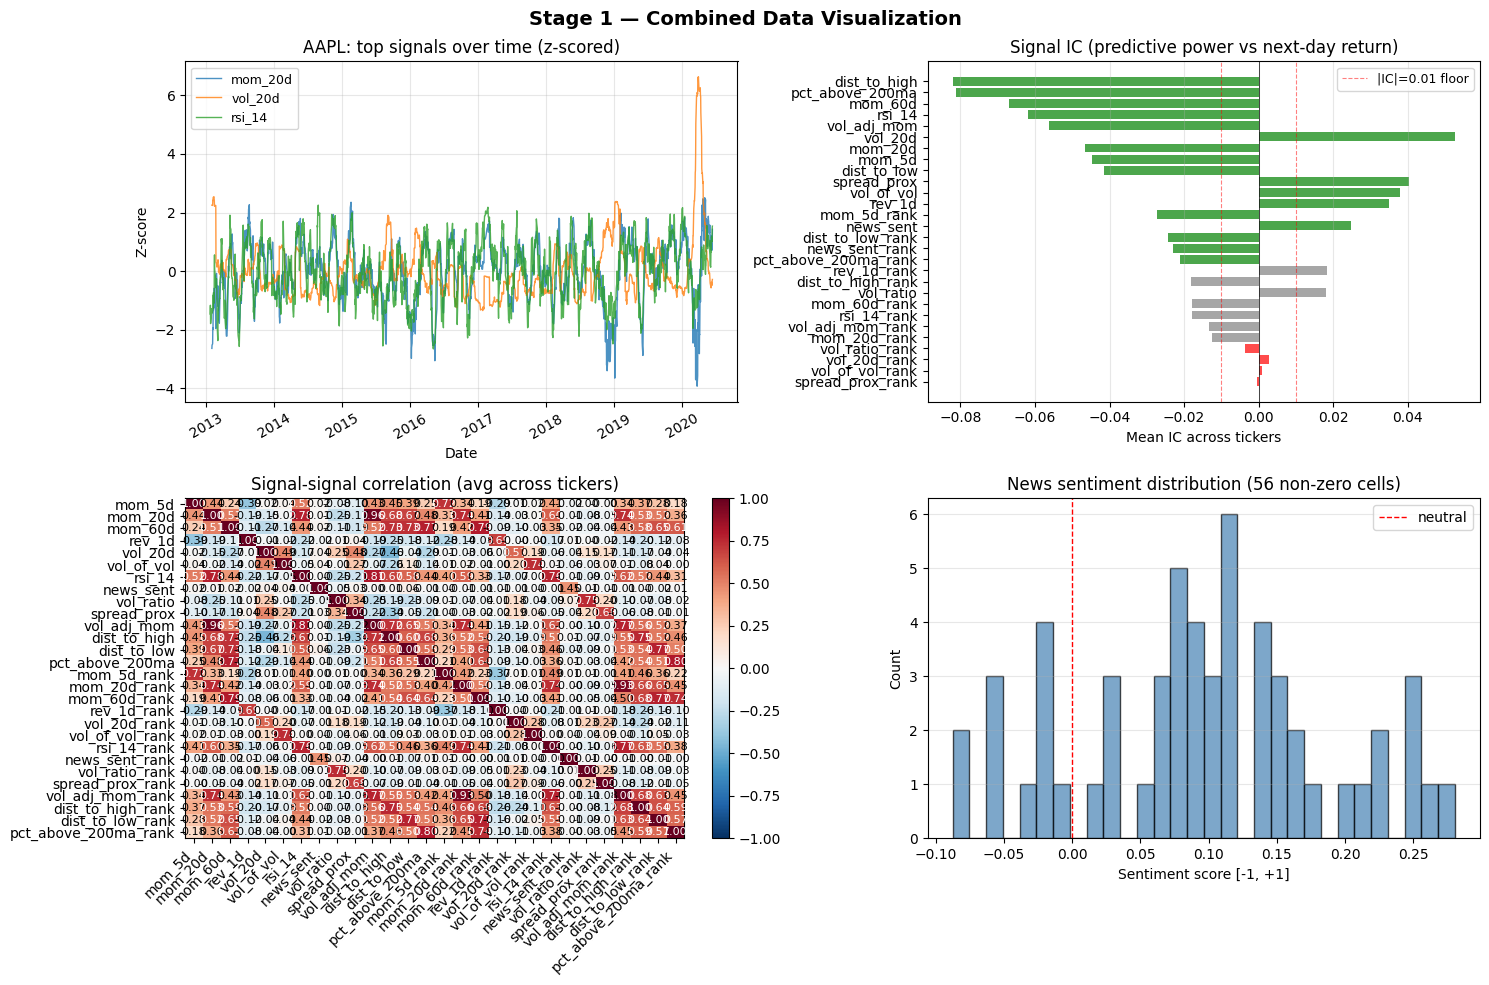


 D. CROSS-SECTION ON A SAMPLE DATE (what Stage 2 alpha model sees)

Date: 2020-04-29
(All 20 tickers x 8 signals + fwd return on this day)



,sector,mom_5d,mom_20d,mom_60d,rev_1d,vol_20d,vol_of_vol,rsi_14,news_sent,vol_ratio,spread_prox,vol_adj_mom,dist_to_high,dist_to_low,pct_above_200ma,mom_5d_rank,mom_20d_rank,mom_60d_rank,rev_1d_rank,vol_20d_rank,vol_of_vol_rank,rsi_14_rank,news_sent_rank,vol_ratio_rank,spread_prox_rank,vol_adj_mom_rank,dist_to_high_rank,dist_to_low_rank,pct_above_200ma_rank,fwd_1d
ticker,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
AAPL,tech,0.0423,0.1330,-0.0081,-0.0328,0.0312,0.0134,64.4670,0.0,0.4756,0.0201,4.2636,-0.1206,0.2824,0.1209,0.50,0.50,0.55,0.50,0.45,0.50,0.90,0.525,0.60,0.10,0.65,0.50,0.30,0.85,0.0211
MSFT,tech,0.0238,0.1264,0.0855,-0.0449,0.0296,0.0163,62.0165,0.0,0.5805,0.0327,4.2723,-0.0572,0.3102,0.1718,0.30,0.45,0.80,0.35,0.35,0.70,0.75,0.525,0.90,0.85,0.70,0.75,0.45,0.90,0.0100
GOOGL,tech,0.0687,0.1564,-0.0528,-0.0889,0.0355,0.0099,68.0915,0.0,1.1269,0.0249,4.4108,-0.1198,0.2733,0.0503,0.65,0.70,0.30,0.05,0.50,0.15,0.95,0.525,1.00,0.50,0.75,0.55,0.25,0.65,0.0034
NVDA,tech,0.0431,0.1435,0.3226,-0.0244,0.0448,0.0172,64.0884,0.0,0.3476,0.0229,3.2041,-0.0510,0.5197,0.3693,0.55,0.65,1.00,0.60,0.80,0.85,0.85,0.525,0.25,0.35,0.25,0.85,0.95,1.00,-0.0207
JPM,fin,0.0925,0.1133,-0.2036,-0.0270,0.0455,0.0149,53.8132,0.0,0.2979,0.0223,2.4912,-0.2835,0.2511,-0.1605,0.80,0.35,0.10,0.55,0.90,0.60,0.30,0.525,0.10,0.30,0.20,0.15,0.15,0.15,-0.0215
BAC,fin,0.1307,0.1755,-0.1733,-0.0373,0.0464,0.0167,55.7876,0.0,0.3626,0.0242,3.7855,-0.2859,0.3706,-0.1555,1.00,0.85,0.15,0.45,0.95,0.80,0.40,0.525,0.35,0.45,0.40,0.10,0.70,0.20,-0.0295
V,fin,0.0895,0.1370,-0.0308,-0.0615,0.0414,0.0116,55.4704,0.0,0.5659,0.0338,3.3066,-0.1478,0.3393,0.0071,0.75,0.55,0.40,0.15,0.70,0.35,0.35,0.525,0.85,0.90,0.30,0.35,0.60,0.55,-0.0169
MA,fin,0.1020,0.1821,-0.0522,-0.0721,0.0454,0.0123,55.8840,0.0,0.5917,0.0308,4.0061,-0.1754,0.3976,0.0064,0.85,0.90,0.35,0.10,0.85,0.45,0.45,0.525,0.95,0.80,0.50,0.30,0.75,0.50,-0.0307
JNJ,hc,-0.0178,0.1407,0.0420,0.0076,0.0212,0.0114,61.9602,0.0,0.3678,0.0164,6.6389,-0.0339,0.3518,0.1054,0.10,0.60,0.70,0.85,0.05,0.30,0.70,0.525,0.40,0.05,0.95,0.95,0.65,0.75,-0.0013



Top-5 mom_20d on 2020-04-29 avg fwd_1d: -0.0205
Bot-5 mom_20d on 2020-04-29 avg fwd_1d: -0.0104
(Negative spread = mom_20d "worked" on this day; one day, not the population)


In [35]:
import matplotlib.pyplot as plt
from IPython.display import display

# ============================================================
# A. Tabular preview — what the combined data actually looks like
# ============================================================
print('=' * 70)
print(' A. SAMPLE OF COMBINED DATA (last 5 trading days, 4 sample tickers)')
print('=' * 70)

sample_tickers = ['AAPL', 'JPM', 'JNJ', 'NVDA']

# Build a tidy preview: one row per (date, ticker), one column per signal + label
preview_rows = []
for t in sample_tickers:
    for d in signals_long.index[-5:]:
        row = {'date': d.date(), 'ticker': t, 'sector': TICKER_SECTOR[t]}
        for s in SIGNALS:
            row[s] = signals_long.loc[d, (t, s)] if (t, s) in signals_long.columns else None
        row['news_sent_raw'] = float(news_sent.loc[d, t]) if d in news_sent.index else 0
        row['regime'] = regime_tags.loc[d] if d in regime_tags.index else ''
        row['fwd_1d'] = float(fwd_1d.loc[d, t]) if d in fwd_1d.index else None
        preview_rows.append(row)

preview_df = pd.DataFrame(preview_rows)
print('\nCombined (date, ticker) view — all features at a glance:')
display(preview_df.round(4))

# ============================================================
# B. News sentiment coverage breakdown by ticker
# ============================================================
print('\n' + '=' * 70)
print(' B. NEWS SENTIMENT COVERAGE BY TICKER')
print('=' * 70)
news_per_ticker = (news_sent != 0).sum().rename('non_zero_days')
news_mean_per_ticker = news_sent.where(news_sent != 0).mean().rename('mean_sent_when_present')
news_summary = pd.DataFrame({
    'non_zero_days': news_per_ticker,
    'coverage_%': (news_per_ticker / len(news_sent) * 100).round(2),
    'mean_sent': news_mean_per_ticker.round(4),
    'sector': pd.Series(TICKER_SECTOR),
}).sort_values('non_zero_days', ascending=False)
print('\nPer-ticker news coverage (top 10):')
display(news_summary.head(10))

# ============================================================
# C. Visualizations — 2x2 grid
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Stage 1 — Combined Data Visualization', fontsize=14, fontweight='bold')

# C1. Signal time series for AAPL (top-left)
ax = axes[0, 0]
ticker_demo = 'AAPL'
plot_signals = ['mom_20d', 'vol_20d', 'rsi_14']
for s in plot_signals:
    series = signals_long[(ticker_demo, s)].dropna()
    normalized = (series - series.mean()) / series.std()  # z-score for comparison
    ax.plot(normalized.index, normalized.values, label=s, alpha=0.8, linewidth=1)
ax.set_title(f'{ticker_demo}: top signals over time (z-scored)')
ax.set_xlabel('Date')
ax.set_ylabel('Z-score')
ax.legend(loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
ax.tick_params(axis='x', rotation=30)

# C2. IC ranking bar chart (top-right)
ax = axes[0, 1]
ic_sorted = pd.Series(ic_results).sort_values(key=abs, ascending=True)
colors = ['red' if abs(v) < 0.01 else 'gray' if abs(v) < 0.02 else 'green' for v in ic_sorted.values]
ax.barh(ic_sorted.index, ic_sorted.values, color=colors, alpha=0.7)
ax.axvline(0, color='black', linewidth=0.5)
ax.axvline(0.01, color='red', linestyle='--', linewidth=0.8, alpha=0.5, label='|IC|=0.01 floor')
ax.axvline(-0.01, color='red', linestyle='--', linewidth=0.8, alpha=0.5)
ax.set_title('Signal IC (predictive power vs next-day return)')
ax.set_xlabel('Mean IC across tickers')
ax.legend(fontsize=9)
ax.grid(alpha=0.3, axis='x')

# C3. Signal correlation heatmap (bottom-left)
ax = axes[1, 0]
im = ax.imshow(sig_corr.values.astype(float), cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(SIGNALS)))
ax.set_yticks(range(len(SIGNALS)))
ax.set_xticklabels(SIGNALS, rotation=45, ha='right')
ax.set_yticklabels(SIGNALS)
for i in range(len(SIGNALS)):
    for j in range(len(SIGNALS)):
        val = sig_corr.values[i, j]
        if not pd.isna(val):
            color = 'white' if abs(val) > 0.5 else 'black'
            ax.text(j, i, f'{val:.2f}', ha='center', va='center', color=color, fontsize=8)
ax.set_title('Signal-signal correlation (avg across tickers)')
plt.colorbar(im, ax=ax, fraction=0.046)

# C4. News sentiment density / distribution (bottom-right)
ax = axes[1, 1]
nz_sentiment = news_sent.values[news_sent.values != 0]
if len(nz_sentiment) > 0:
    ax.hist(nz_sentiment, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
    ax.axvline(0, color='red', linestyle='--', linewidth=1, label='neutral')
    ax.set_title(f'News sentiment distribution ({len(nz_sentiment)} non-zero cells)')
    ax.set_xlabel('Sentiment score [-1, +1]')
    ax.set_ylabel('Count')
    ax.legend()
    ax.grid(alpha=0.3, axis='y')
else:
    ax.text(0.5, 0.5, 'No news sentiment data', ha='center', va='center',
            transform=ax.transAxes, fontsize=12)
    ax.set_title('News sentiment distribution')

plt.tight_layout()
plt.show()

# ============================================================
# D. Cross-section view — what an alpha model sees on one day
# ============================================================
print('\n' + '=' * 70)
print(' D. CROSS-SECTION ON A SAMPLE DATE (what Stage 2 alpha model sees)')
print('=' * 70)
sample_date = signals_long.index[-30]  # 30 days ago
print(f'\nDate: {sample_date.date()}')
print(f'(All 20 tickers x 8 signals + fwd return on this day)\n')

cross_section = []
for t in TICKERS:
    row = {'ticker': t, 'sector': TICKER_SECTOR[t]}
    for s in SIGNALS:
        row[s] = signals_long.loc[sample_date, (t, s)] if (t, s) in signals_long.columns else None
    row['fwd_1d'] = float(fwd_1d.loc[sample_date, t]) if sample_date in fwd_1d.index else None
    cross_section.append(row)
cs_df = pd.DataFrame(cross_section).set_index('ticker')
display(cs_df.round(4))

# Quick check: did high mom_20d on this date predict positive fwd return?
high_mom = cs_df.nlargest(5, 'mom_20d')
low_mom  = cs_df.nsmallest(5, 'mom_20d')
print(f'\nTop-5 mom_20d on {sample_date.date()} avg fwd_1d: {high_mom["fwd_1d"].mean():+.4f}')
print(f'Bot-5 mom_20d on {sample_date.date()} avg fwd_1d: {low_mom["fwd_1d"].mean():+.4f}')
print(f'(Negative spread = mom_20d "worked" on this day; one day, not the population)')

## 8. Stage readiness summary

Final GO/NO-GO per downstream stage. **If a stage shows STOP, fix the failing checks before proceeding.**

In [36]:
def stage_status(prereq_prefixes):
    relevant = {n: v for n, v in CHECKS.items()
                if any(n.startswith(p) for p in prereq_prefixes)}
    fails = [(n, v[1]) for n, v in relevant.items() if v[0] == 'FAIL']
    warns = [(n, v[1]) for n, v in relevant.items() if v[0] == 'WARN']
    if fails:
        return 'STOP', f'{len(fails)} failed', fails
    if warns:
        return 'GO (with warnings)', f'{len(warns)} warnings', warns
    return 'GO', 'all green', []

print('=' * 72)
print(' STAGE READINESS SUMMARY')
print('=' * 72)

stages = [
    ('Stage 2 (Alpha models)',
     ['OHLCV', 'Returns', 'Signals', 'Signal ', 'Forward'],
     'needs OHLCV + computable signals + forward returns'),
    ('Stage 3 (Meta-labeling) — HEADLINE',
     ['Signals', 'Signal ', 'Forward'],
     'needs signal variety + balanced labels'),
    ('Stage 4 (QAOA portfolio)',
     ['OHLCV', 'Returns', 'Universe'],
     'needs returns for covariance + sector tags'),
    ('Stage 5.5 (Q-Atlas demo)',
     ['Regime'],
     'needs regime-tagged dates for human-readable analogs'),
]

for name, prefixes, desc in stages:
    status, msg, issues = stage_status(prefixes)
    print(f'\n  {name}')
    print(f'    prereqs: {desc}')
    print(f'    --> {status}: {msg}')
    for n, m in issues:
        print(f'         - {n}: {m}')

print()
print('=' * 72)
all_critical_fail = [n for n, (s, _) in CHECKS.items() if s == 'FAIL']
if all_critical_fail:
    print(f' OVERALL: RED — {len(all_critical_fail)} critical check(s) failed')
    print(' Fix these before moving to Stage 2:')
    for n in all_critical_fail:
        print(f'   - {n}: {CHECKS[n][1]}')
else:
    print(' OVERALL: GREEN — data is ready for Stage 2 (alpha models)')
    print(f'   Outputs in {DATA_DIR}:')
    print('     - prices.parquet, returns.parquet, volumes.parquet')
    print('     - news_sent.parquet, fama_french.parquet')
    print('     - signals.parquet, regime_tags.parquet')
    print('     - forward_returns_1d.parquet, forward_returns_5d.parquet')
    print('     - ticker_sector.csv, ic_ranking.csv, signal_correlations.csv')
print('=' * 72)

# Persist the check log for downstream notebooks
with open(os.path.join(DATA_DIR, 'stage1_checks.json'), 'w') as f:
    json.dump({n: {'status': s, 'msg': m} for n, (s, m) in CHECKS.items()}, f, indent=2)

 STAGE READINESS SUMMARY

  Stage 2 (Alpha models)
    prereqs: needs OHLCV + computable signals + forward returns
    --> GO: all green

  Stage 3 (Meta-labeling) — HEADLINE
    prereqs: needs signal variety + balanced labels
    --> GO: all green

  Stage 4 (QAOA portfolio)
    prereqs: needs returns for covariance + sector tags
    --> GO: all green

  Stage 5.5 (Q-Atlas demo)
    prereqs: needs regime-tagged dates for human-readable analogs
    --> GO: all green

 OVERALL: GREEN — data is ready for Stage 2 (alpha models)
   Outputs in /Applications/Projects/Hackathons/quantum_ai/workspace/data:
     - prices.parquet, returns.parquet, volumes.parquet
     - news_sent.parquet, fama_french.parquet
     - signals.parquet, regime_tags.parquet
     - forward_returns_1d.parquet, forward_returns_5d.parquet
     - ticker_sector.csv, ic_ranking.csv, signal_correlations.csv
